# Лабораторная работа № 6. Деревья решений и ансамблевые методы
## Ноутбук 1. Этапы 0–2: загрузка данных, EDA, предобработка и разбиение

**Вариант 3.** Датасет: выявление мошенничества с кредитными картами (`credit_card_fraud_2026.csv`).
**Задача:** определить мошеннические транзакции (бинарная классификация, целевая переменная `is_fraud`).
**Методы аналитического проекта:** Random Forest + Gradient Boosting + Stacking.

In [1]:
# 1. Импорт библиотек
import sys
import random
import warnings

sys.path.append("../src")                       # модули проекта лежат в папке src

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_class_weight

from common import (DATA_PATH, SEED, TARGET, CLASS_NAMES, load_data, get_feature_lists,
                    make_preprocessor, split_data, split_train_val, get_feature_names,
                    make_pipeline_dt, save_fig)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# 2. Фиксация генератора случайных чисел
random.seed(SEED)
np.random.seed(SEED)

## ЭТАП 0. Загрузка и первичное знакомство с данными

In [2]:
# Задание 0.1. Загрузка датасета: shape, dtypes, head()
df_raw = pd.read_csv(DATA_PATH)
print("shape:", df_raw.shape)
print()
print(df_raw.dtypes)

shape: (20000, 26)

transaction_id                    int64
amount_usd                      float64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
is_ai_generated_scam_attempt       bool
merchant_risk_score             float64
prior_disputes      

In [3]:
df_raw.head()

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,22.35,39,25,1080.71,False,False,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,35.28,47,33,4463.72,True,False,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,9.82,51,59,366.25,False,True,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,19.72,48,28,1345.29,True,False,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,17.68,43,36,4192.59,False,False,False,False,0,3.9,2,4,False,32.7,0,0


**Целевая переменная** – `is_fraud` (1 – мошенническая транзакция, 0 – легитимная).
`transaction_id` – уникальный идентификатор строки, информации о мошенничестве не несёт, поэтому в признаки не включается.
Булевы столбцы (`is_foreign_transaction`, `used_vpn` и т. д.) – бинарные флаги, переводятся в 0/1.

In [4]:
# Задание 0.2. Целевая переменная и признаки, числовые / категориальные
df = load_data()                                # булевы столбцы переведены в 0/1
numeric_cols, categorical_cols = get_feature_lists(df)
flag_cols = [c for c in df_raw.columns if df_raw[c].dtype == "bool"]
continuous_cols = [c for c in numeric_cols if c not in flag_cols]

print("Целевая переменная:", TARGET)
print("transaction_id уникален:", df["transaction_id"].is_unique, "(идентификатор, в признаки не входит)")
print(f"\nЧисловые непрерывные/счётные ({len(continuous_cols)}):", continuous_cols)
print(f"\nБинарные флаги ({len(flag_cols)}):", flag_cols)
print(f"\nКатегориальные ({len(categorical_cols)}):", categorical_cols)
print("\nЧисло уникальных значений категориальных признаков:")
print(df[categorical_cols].nunique().to_string())

Целевая переменная: is_fraud
transaction_id уникален: True (идентификатор, в признаки не входит)

Числовые непрерывные/счётные (13): ['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']

Бинарные флаги (6): ['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']

Категориальные (5): ['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']

Число уникальных значений категориальных признаков:
merchant_category    12
card_type             5
auth_method           5
channel               5
device_type           8


In [5]:
# Задание 0.3. Пропуски: количество и доля по каждой колонке
missing = pd.DataFrame({"пропусков": df.isna().sum(), "доля, %": (df.isna().mean() * 100).round(2)})
print(missing.T.to_string())
print("\nВсего пропусков в датасете:", int(df.isna().sum().sum()))
print("Полных дубликатов строк (без id):", int(df.drop(columns="transaction_id").duplicated().sum()))

           transaction_id  amount_usd  merchant_category  card_type  auth_method  channel  device_type  is_foreign_transaction  hours_since_last_txn  txn_count_last_24h  distance_from_home_km  card_age_months  customer_age  account_balance_usd  is_new_merchant  used_vpn  ip_country_mismatch  billing_shipping_mismatch  cvv_retry_count  velocity_score  time_of_day_hour  day_of_week  is_ai_generated_scam_attempt  merchant_risk_score  prior_disputes  is_fraud
пропусков             0.0         0.0                0.0        0.0          0.0      0.0          0.0                     0.0                   0.0                 0.0                    0.0              0.0           0.0                  0.0              0.0       0.0                  0.0                        0.0              0.0             0.0               0.0          0.0                           0.0                  0.0             0.0       0.0
доля, %               0.0         0.0                0.0        0.0          0.0

**Стратегия по пропускам:** пропусков нет ни в одной колонке, поэтому заполнение, удаление строк и флаги пропуска не требуются.
Дубликатов строк также нет.

In [6]:
# Задание 0.4. Распределение классов и коэффициент дисбаланса
counts = df[TARGET].value_counts().sort_index()
shares = df[TARGET].value_counts(normalize=True).sort_index()
imbalance = counts.min() / counts.max()          # доля меньшинства / доля большинства

print(pd.DataFrame({"объектов": counts.values, "доля, %": (shares * 100).round(3).values}, index=CLASS_NAMES).to_string())
print(f"\nКоэффициент дисбаланса (меньшинство / большинство) = {imbalance:.4f}")
print(f"Соотношение классов ≈ 1 : {counts.max() / counts.min():.1f}")

               объектов  доля, %
Легитимно         19661   98.305
Мошенничество       339    1.695

Коэффициент дисбаланса (меньшинство / большинство) = 0.0172
Соотношение классов ≈ 1 : 58.0


In [7]:
# Результат этапа 0: сводная таблица
summary = pd.DataFrame({
    "Показатель": ["Строк", "Колонок (вместе с id и целью)", "Колонок с пропусками",
                   "Доля класса 0 (легитимно), %", "Доля класса 1 (мошенничество), %", "Коэффициент дисбаланса"],
    "Значение": [str(df.shape[0]), str(df.shape[1]), str(int((df.isna().sum() > 0).sum())),
                 f"{shares[0] * 100:.2f}", f"{shares[1] * 100:.2f}", f"{imbalance:.4f}"],
})
summary

,Показатель,Значение
0,Строк,20000
1,Колонок (вместе с id и целью),26
2,Колонок с пропусками,0
3,"Доля класса 0 (легитимно), %",98.30
4,"Доля класса 1 (мошенничество), %",1.70
5,Коэффициент дисбаланса,0.0172


## ЭТАП 1. Разведочный анализ данных (EDA)

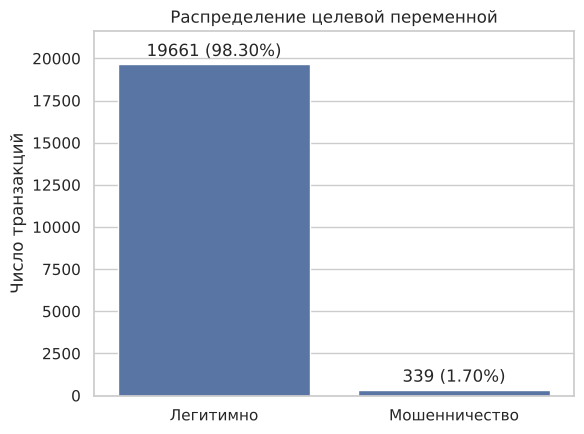

In [8]:
# Задание 1.1. Распределение целевой переменной (countplot) с процентами
df_plot = df.assign(is_fraud_label=df[TARGET].map({0: "Легитимно", 1: "Мошенничество"}))

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.countplot(data=df_plot, x="is_fraud_label", order=CLASS_NAMES, color="#4c72b0", ax=ax)
ax.bar_label(ax.containers[0], labels=[f"{n} ({n / len(df):.2%})" for n in counts.values], padding=3)
ax.set_title("Распределение целевой переменной")
ax.set_xlabel("")
ax.set_ylabel("Число транзакций")
ax.set_ylim(0, counts.max() * 1.1)
plt.tight_layout()
save_fig("01_target_distribution")
plt.show()

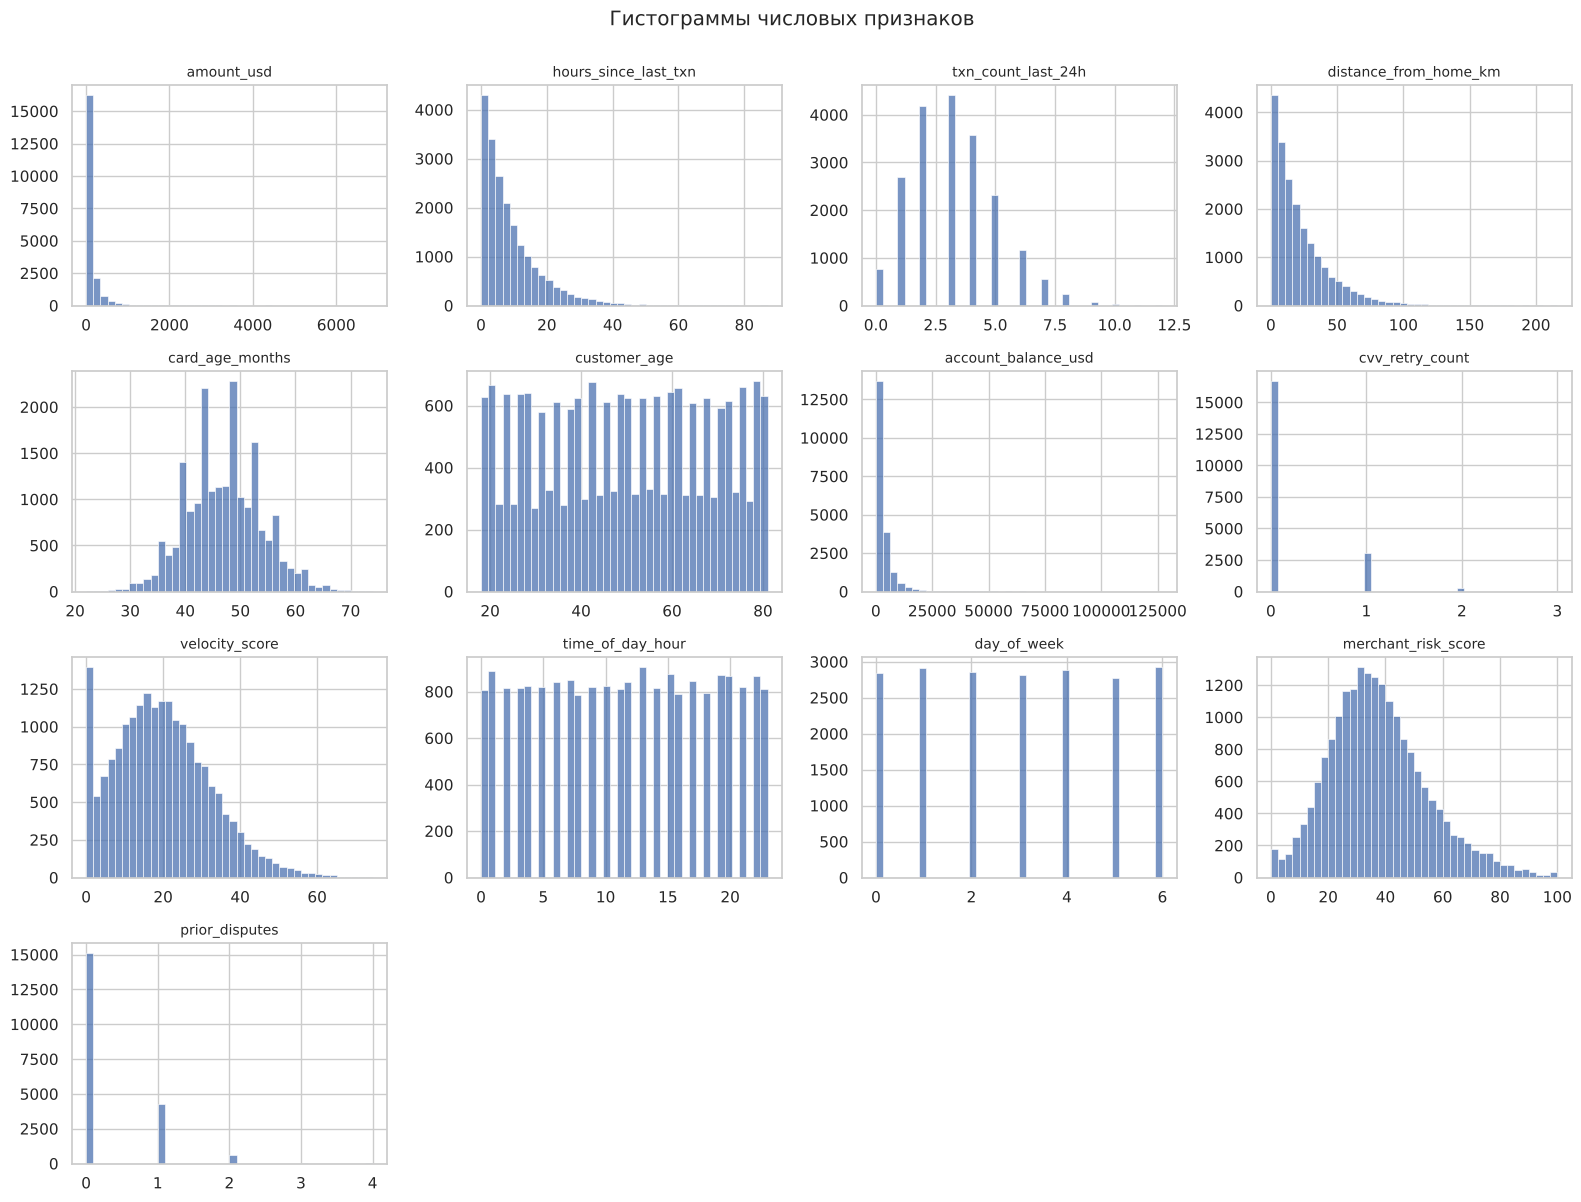

In [9]:
# Задание 1.2. Числовые признаки: гистограммы
fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.ravel(), continuous_cols):
    sns.histplot(df[col], bins=40, color="#4c72b0", ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
for ax in axes.ravel()[len(continuous_cols):]:
    ax.axis("off")                                # лишние оси скрываем
plt.suptitle("Гистограммы числовых признаков", y=1.0)
plt.tight_layout()
save_fig("02_numeric_hist")
plt.show()

In [10]:
# Выбросы по правилу 1.5*IQR (boxplot): доля наблюдений за «усами»
def outlier_share(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean() * 100

out_table = (df[continuous_cols].apply(outlier_share).round(1)
             .sort_values(ascending=False).rename("доля выбросов, %").to_frame())
print(out_table.T.to_string())

                  prior_disputes  cvv_retry_count  amount_usd  account_balance_usd  hours_since_last_txn  distance_from_home_km  merchant_risk_score  txn_count_last_24h  velocity_score  card_age_months  customer_age  day_of_week  time_of_day_hour
доля выбросов, %            24.6             16.7        10.3                  7.8                   4.8                    4.5                  1.8                 1.7             1.1              0.9           0.0          0.0               0.0


Признаки `amount_usd` (10,3% выбросов), `account_balance_usd` (7,8%), `hours_since_last_txn` (4,8%) и `distance_from_home_km` (4,5%) имеют сильно скошенные
распределения с длинным правым «хвостом». У счётных признаков `prior_disputes` (24,6%) и `cvv_retry_count` (16,7%) «выбросами» оказываются редкие ненулевые значения.
Это реальные наблюдения, а не ошибки, поэтому из выборки они не удаляются; для деревьев и ансамблей на деревьях выбросы не критичны.

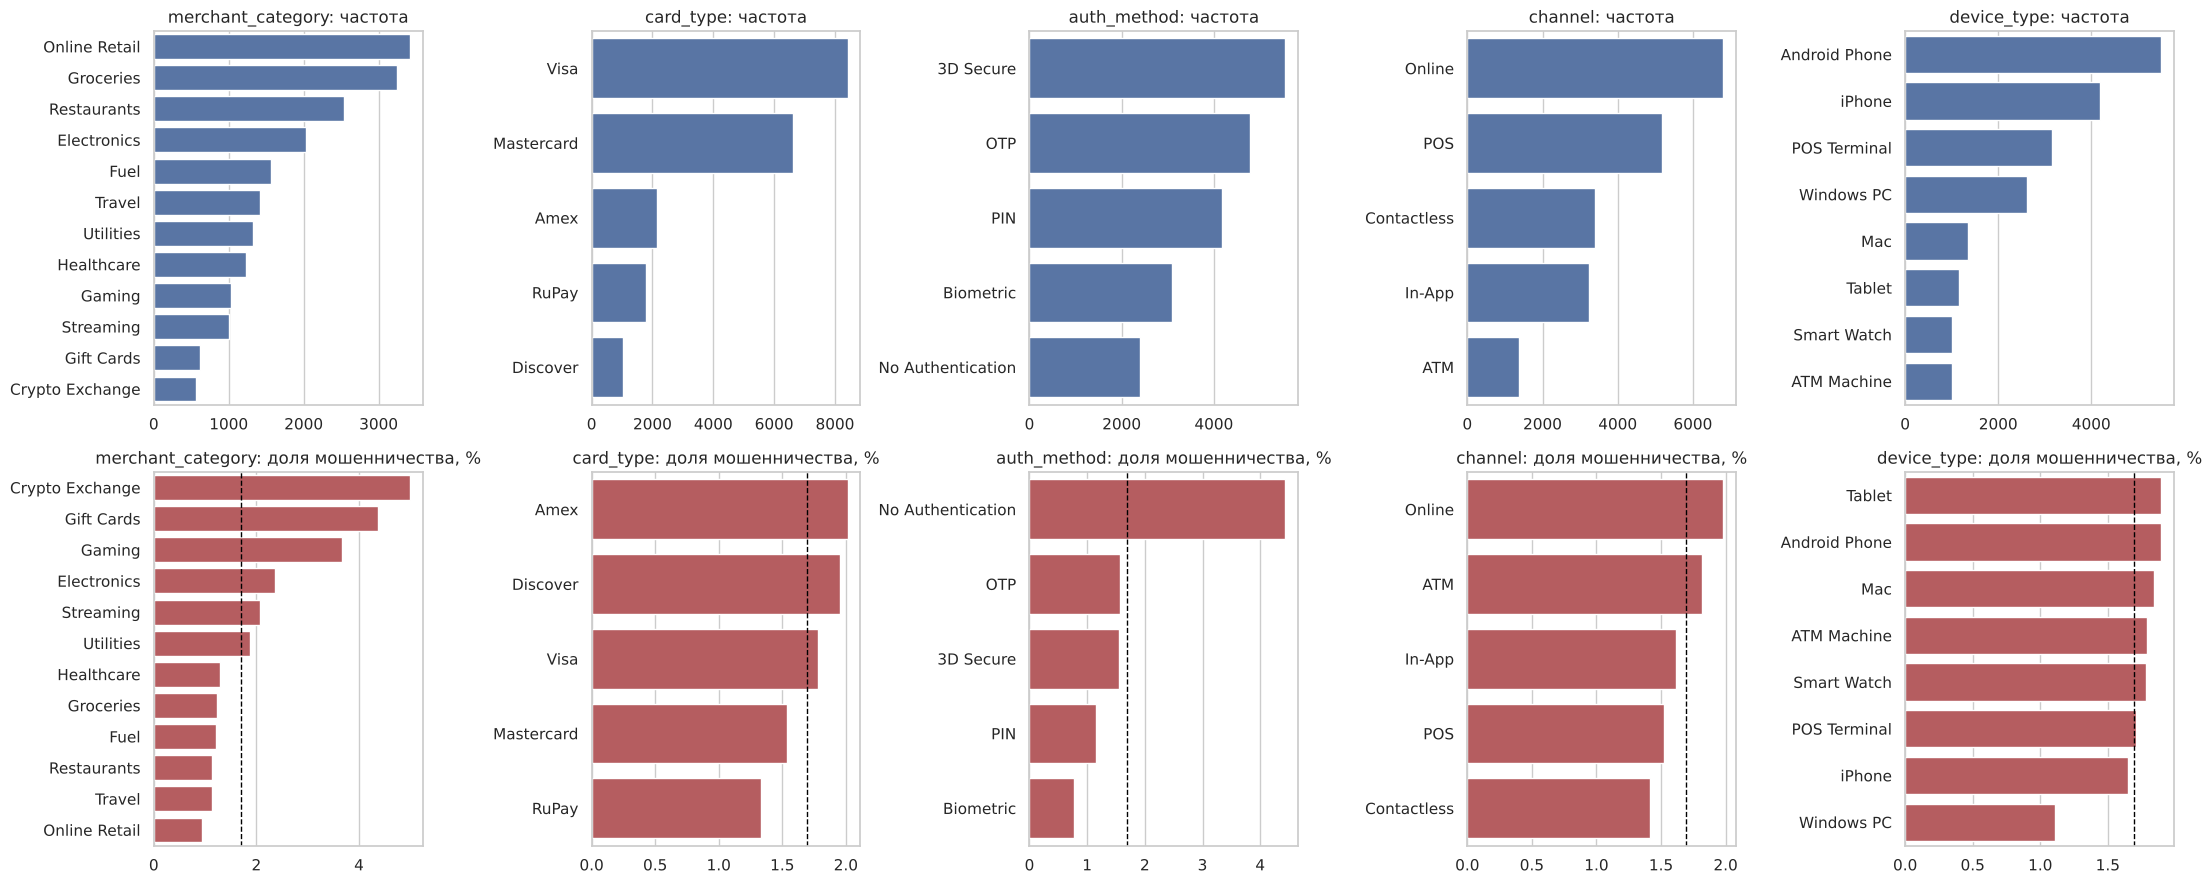

In [11]:
# Задание 1.3. Категориальные признаки: частоты и доля мошенничества по категориям
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
for j, col in enumerate(categorical_cols):
    freq = df[col].value_counts()
    sns.barplot(x=freq.values, y=freq.index, color="#4c72b0", ax=axes[0, j])
    axes[0, j].set_title(f"{col}: частота")
    axes[0, j].set_xlabel("")
    axes[0, j].set_ylabel("")
    rate = (df.groupby(col)[TARGET].mean() * 100).sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, color="#c44e52", ax=axes[1, j])
    axes[1, j].axvline(df[TARGET].mean() * 100, color="black", ls="--", lw=1)
    axes[1, j].set_title(f"{col}: доля мошенничества, %")
    axes[1, j].set_xlabel("")
    axes[1, j].set_ylabel("")
plt.tight_layout()
save_fig("03_categorical")
plt.show()

In [12]:
# Доля мошенничества по категориям (максимум и минимум) для оценки информативности
for col in categorical_cols:
    rate = (df.groupby(col)[TARGET].mean() * 100).round(2)
    print(f"{col:18s} max: {rate.idxmax():18s} {rate.max():5.2f}%   min: {rate.idxmin():18s} {rate.min():5.2f}%")
print(f"\nСредняя доля мошенничества по выборке: {df[TARGET].mean() * 100:.2f}%")

merchant_category  max: Crypto Exchange     4.99%   min: Online Retail       0.94%
card_type          max: Amex                2.01%   min: RuPay               1.34%
auth_method        max: No Authentication   4.44%   min: Biometric           0.78%
channel            max: Online              1.98%   min: Contactless         1.41%
device_type        max: Android Phone       1.89%   min: Windows PC          1.11%

Средняя доля мошенничества по выборке: 1.70%


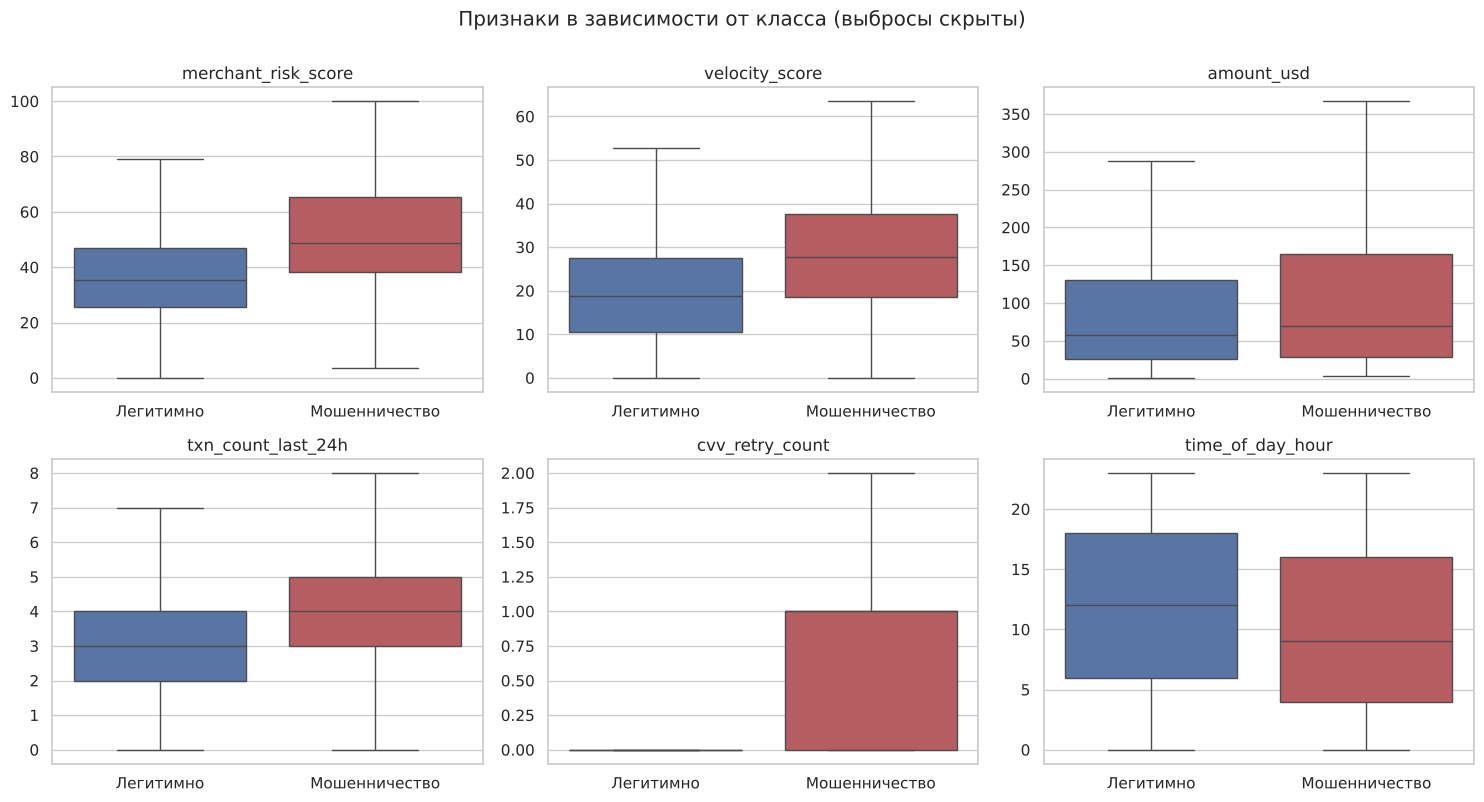

In [13]:
# Задание 1.4. Связь признаков с целевой переменной: boxplot с группировкой по классу
top_features = ["merchant_risk_score", "velocity_score", "amount_usd", "txn_count_last_24h",
                "cvv_retry_count", "time_of_day_hour"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), top_features):
    sns.boxplot(data=df_plot, x="is_fraud_label", y=col, order=CLASS_NAMES, showfliers=False,
                hue="is_fraud_label", palette=["#4c72b0", "#c44e52"], legend=False, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.suptitle("Признаки в зависимости от класса (выбросы скрыты)", y=1.0)
plt.tight_layout()
save_fig("04_numeric_vs_target")
plt.show()

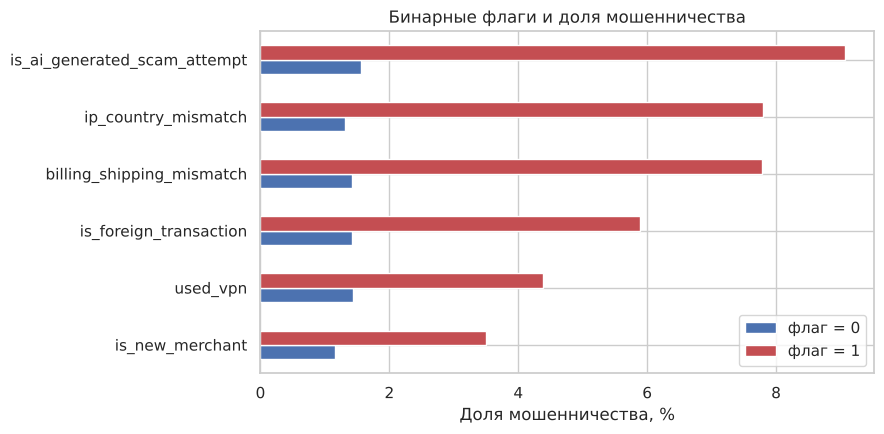

,флаг = 0,флаг = 1
is_new_merchant,1.16,3.50
used_vpn,1.44,4.38
is_foreign_transaction,1.42,5.89
billing_shipping_mismatch,1.42,7.79
ip_country_mismatch,1.32,7.80
is_ai_generated_scam_attempt,1.55,9.07


In [14]:
# Бинарные флаги: доля мошенничества при значении флага 0 и 1
flag_rate = pd.DataFrame({f: df.groupby(f)[TARGET].mean() * 100 for f in flag_cols}).T
flag_rate.columns = ["флаг = 0", "флаг = 1"]
flag_rate = flag_rate.sort_values("флаг = 1")
ax = flag_rate.plot(kind="barh", figsize=(9, 4.5), color=["#4c72b0", "#c44e52"])
ax.set_xlabel("Доля мошенничества, %")
ax.set_title("Бинарные флаги и доля мошенничества")
plt.tight_layout()
save_fig("05_flags_vs_target")
plt.show()
flag_rate.round(2)

In [15]:
# Сила связи числовых признаков и флагов с целевой переменной (корреляция Спирмена)
corr = pd.Series({c: spearmanr(df[c], df[TARGET])[0] for c in numeric_cols}).sort_values(key=abs, ascending=False)
corr.round(3).rename("Spearman с is_fraud").to_frame().head(12)

,Spearman с is_fraud
cvv_retry_count,0.139
ip_country_mismatch,0.118
billing_shipping_mismatch,0.101
merchant_risk_score,0.095
velocity_score,0.086
is_foreign_transaction,0.083
is_ai_generated_scam_attempt,0.079
is_new_merchant,0.076
used_vpn,0.065
txn_count_last_24h,0.055


**Какие признаки выглядят связанными с целевой переменной.** Наиболее заметна связь у `cvv_retry_count`
(у легитимных транзакций повторных вводов CVV почти нет), у флагов `ip_country_mismatch`, `billing_shipping_mismatch`,
`is_foreign_transaction`, `is_ai_generated_scam_attempt`, `used_vpn`, `is_new_merchant` (доля мошенничества при флаге = 1
в 3–6 раз выше, чем при 0), а также у `merchant_risk_score`, `velocity_score` и `txn_count_last_24h` (у мошеннических
транзакций они выше). Среди категорий информативны `merchant_category` (Crypto Exchange 5,0%, Gift Cards 4,4%, Gaming 3,7%
против 1,7% в среднем) и `auth_method` (No Authentication 4,4%). Признаки `card_type`, `channel`, `device_type`, `day_of_week`,
`card_age_months`, `distance_from_home_km`, `account_balance_usd`, `amount_usd` между классами почти не различаются.
Связи слабые и нелинейные (коэффициенты Спирмена не превышают 0,14), поэтому для задачи подходят модели на деревьях.

## ЭТАП 2. Предобработка данных и разбиение

In [16]:
# Задание 2.1. Сначала разбиение train/test (stratify=y, random_state=42) – только потом предобработка
X_train, X_test, y_train, y_test = split_data(df)

split_table = pd.DataFrame({
    "объектов": [len(X_train), len(X_test)],
    "мошеннических": [int(y_train.sum()), int(y_test.sum())],
    "доля мошеннических, %": [round(y_train.mean() * 100, 3), round(y_test.mean() * 100, 3)],
}, index=["train (80%)", "test (20%)"])
split_table

,объектов,мошеннических,"доля мошеннических, %"
train (80%),16000,271,1.694
test (20%),4000,68,1.700


In [17]:
# Из обучающей выборки выделяем validation-выборку: по ней подбираются гиперпараметры (этап 4).
# Test используется только для итогового сравнения.
X_fit, X_val, y_fit, y_val = split_train_val(X_train, y_train, val_size=0.25)

pd.DataFrame({
    "объектов": [len(X_fit), len(X_val), len(X_test)],
    "мошеннических": [int(y_fit.sum()), int(y_val.sum()), int(y_test.sum())],
}, index=["train-fit (60%)", "validation (20%)", "test (20%)"])

,объектов,мошеннических
train-fit (60%),12000,203
validation (20%),4000,68
test (20%),4000,68


**Масштабирование числовых признаков.** `StandardScaler` не применяется: деревья решений, Random Forest и Gradient Boosting
выбирают порог разбиения по одному признаку и инвариантны к монотонным преобразованиям шкалы, поэтому стандартизация
на качество не влияет. Масштабирование используется только внутри линейных моделей (логистическая регрессия) в Stacking.

**Категориальные признаки.** Используется `OneHotEncoder(handle_unknown="ignore")`: категории не упорядочены,
порядковое кодирование (`LabelEncoder`) навязало бы им ложный порядок.

In [18]:
# Задания 2.2–2.3. Предобработка: числа – как есть, категории – OneHotEncoder (обучается только на train)
preprocessor = make_preprocessor(numeric_cols, categorical_cols)
preprocessor.fit(X_train)

X_train_t = preprocessor.transform(X_train)
feature_names = get_feature_names(preprocessor)
print("Признаков до предобработки:", X_train.shape[1])
print("Признаков после предобработки:", X_train_t.shape[1], "(=", len(numeric_cols), "числовых +",
      X_train_t.shape[1] - len(numeric_cols), "one-hot )")
print("\nПервые 5 имён после кодирования:", feature_names[len(numeric_cols):len(numeric_cols) + 5])

Признаков до предобработки: 24
Признаков после предобработки: 54 (= 19 числовых + 35 one-hot )

Первые 5 имён после кодирования: ['merchant_category_Crypto Exchange', 'merchant_category_Electronics', 'merchant_category_Fuel', 'merchant_category_Gaming', 'merchant_category_Gift Cards']


In [19]:
# Задание 2.4. Дисбаланс (1 : 58 > 3 : 1) – применяется class_weight="balanced" (только на train)
classes = np.array([0, 1])
weights = compute_class_weight("balanced", classes=classes, y=y_train)
print("Веса классов (balanced):", dict(zip(classes.tolist(), weights.round(3).tolist())))
print("Вес редкого класса больше веса класса большинства в", round(weights[1] / weights[0], 1), "раз")

Веса классов (balanced): {0: 0.509, 1: 29.52}
Вес редкого класса больше веса класса большинства в 58.0 раз


**Борьба с дисбалансом.** Методичка допускает `class_weight="balanced"` или SMOTE. Используется `class_weight="balanced"`:
ошибка на редком классе штрафуется в ~58 раз сильнее, при этом синтетические объекты не создаются, а test-выборка остаётся нетронутой.
Для Random Forest применяется вариант `balanced_subsample` (веса пересчитываются в каждой bootstrap-выборке),
для Gradient Boosting – эквивалентные веса объектов (`sample_weight`, см. ноутбук 3).

In [20]:
# Задание 2.5. Предобработка и модель в одном Pipeline (пример для дерева решений)
pipe_example = make_pipeline_dt(preprocessor, max_depth=3)
pipe_example.fit(X_train, y_train)               # препроцессинг обучается внутри fit и только на train
print(pipe_example)
print("\nTest accuracy (пример):", round(pipe_example.score(X_test, y_test), 4))

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['amount_usd',
                                                   'is_foreign_transaction',
                                                   'hours_since_last_txn',
                                                   'txn_count_last_24h',
                                                   'distance_from_home_km',
                                                   'card_age_months',
                                                   'customer_age',
                                                   'account_balance_usd',
                                                   'is_new_merchant',
                                                   'used_vpn',
                                                   'ip_country_mismatch',
                                                   'billing_shipping_mismatch',
                                       

### Итоги этапов 0–2
* Размер данных: 20 000 строк × 26 колонок; пропусков и дубликатов нет.
* Классы сильно несбалансированы: 98,3% / 1,7% (1 : 58) – accuracy не подходит как основная метрика, используются ROC-AUC, F1, Recall, G-mean.
* Разбиение: train 16 000 (из них validation 4 000 для подбора параметров) / test 4 000, стратифицированное, random_state = 42.
* Пайплайн: split → OneHotEncoder (категории) → числа без масштабирования → class_weight="balanced"; всё внутри `Pipeline`, утечки данных нет.